# Artificial project dataset

The [MT dataset](https://www.projectmanagement.ugent.be/research/project_scheduling/rcpsp) was originally created to test the algorithms described in the book *Measuring Time* [1] and has since been used in several studies. In this work, we use a subset of 900 Activity-on-the-Node (AoN) networks, each consisting of 30 activities with randomly assigned durations and costs. The dataset used here is located in the folder `dataset/set1SP`. The topological structure of these networks is determined by the SP-factor, which ranges from 0.1 to 0.9 in increments of 0.1 (100 networks are generated for each SP value).

The SP-factor, introduced by Vanhoucke along with other indicators of topological complexity [2], serves to estimate the difficulty of a project scheduling problem. As the original dataset does not include these indicators for all samples, we compute them in this notebook.

> References:
> 1. Vanhoucke, M. (2009). Measuring time: Improving project performance using earned value management (Vol. 136). Springer Science & Business Media.
> 2. Vanhoucke, M., Coelho, J., Debels, D., & Tavares, L. (2004). On the morphological structure of a network.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import os

In [2]:
from tools import read_dag_file, compute_topological_indicators, compute_times

In [3]:
sns.set_theme(palette='tab10')

## Topological complexity of the dataset

In [4]:
# Read the original dataset of networks and compute the topological indicators
root, _, files = next(os.walk('data\\set1SP'))
networks = [(file.lower().split('.')[0],os.path.join(root, file)) for file in files if file.endswith('rcp')]

In [ ]:
# Compute the topological indicators and other features for each project
project_features = []
for project_name, project_path in networks:
    features=[project_name]
    G = read_dag_file(project_path)
    features.extend([G.number_of_nodes(),G.number_of_edges()])
    sp, ad, la, tf = compute_topological_indicators(G)
    features.extend([sp, ad, la, tf])
    pert_duration = np.max([t for t in compute_times(G,time='duration0')[1].values()]) # baseline duration based on mean durations
    features.append(pert_duration)
    # Save the project features to a CSV file
    pd.DataFrame([features], columns=['Project','Nodes','Edges','SP','AD','LA','TF','PertDuration']).to_csv(f"./montecarlo/{project_name}_topological_indicators.csv", index=False)
    project_features.append(features)

In [19]:
df_projects = pd.DataFrame(project_features, columns=['Project','Nodes','Edges','SP','AD','LA','TF','PertDuration'])

In [ ]:
# Number of projects per SP value
df_projects[['Project','SP']].groupby('SP').count()

,Project
SP,
0.068966,100
0.172414,100
0.275862,100
0.379310,100
0.482759,100
0.586207,100
0.689655,100
0.793103,100
0.896552,100


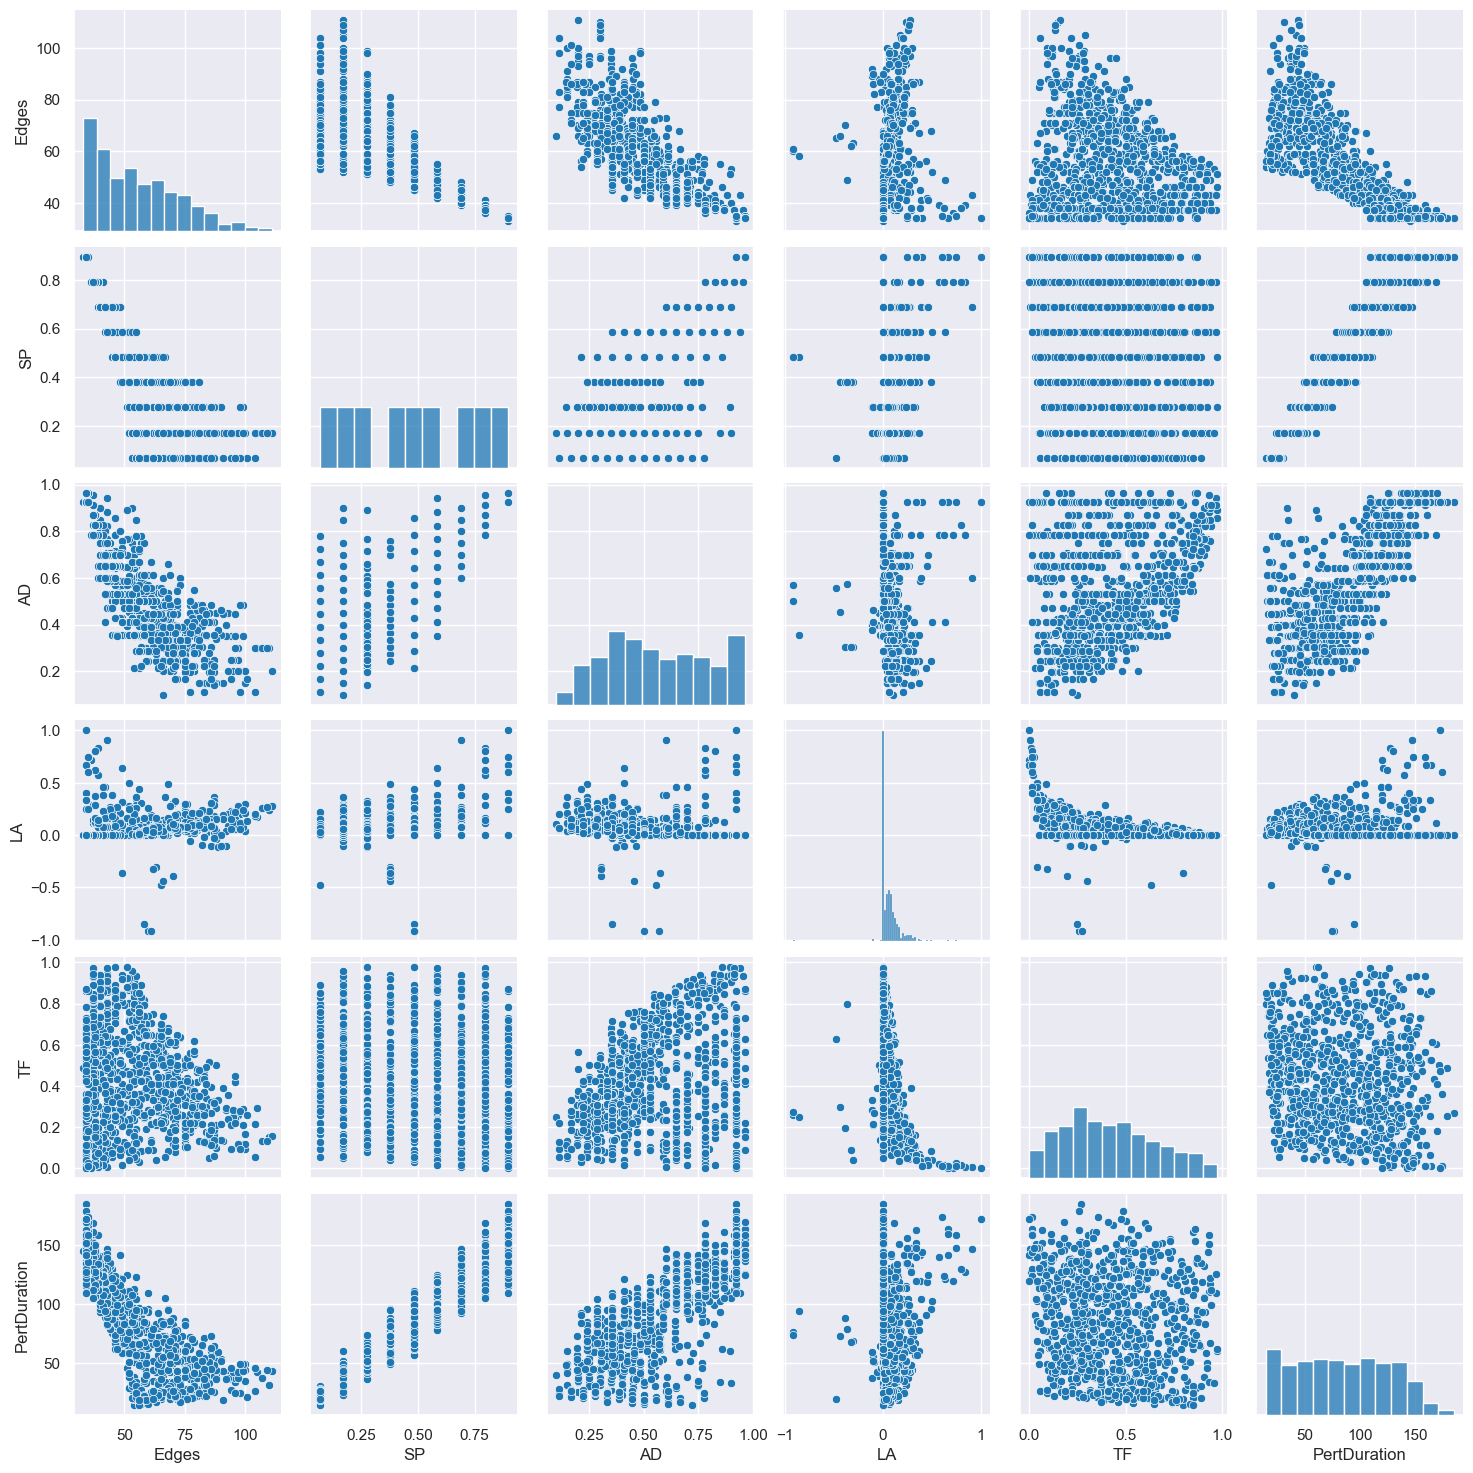

In [ ]:
# Distribution of all pairwise relationships
sns.pairplot(df_projects[['Edges','SP','AD','LA','TF','PertDuration']])

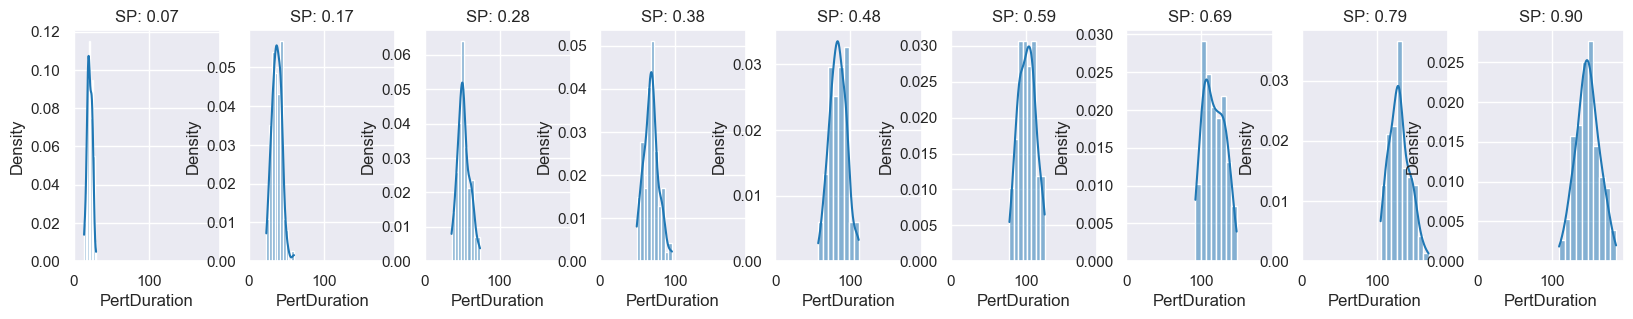

In [31]:
# Histogram of Pert durations for each SP value
plt.figure(figsize=(20, 3))
for i,sp in enumerate(df_projects['SP'].unique()):
    subset = df_projects[df_projects['SP'] == sp]
    plt.subplot(1,9,i+1)
    sns.histplot(subset['PertDuration'], stat='density',kde=True)
    plt.xlim(0,195)
    plt.title(f'SP: {sp:.2f}')
plt.show()